# Plan 15: Fisher-Regularized Memory

Continual learning with scarce observations and compute: acquire new information while retaining predictions after replay eviction.

## Execution progress

| Measure | Status |
| --- | --- |
| Execution status | completed |
| Phase / protocol | 4 / plan15-v1 |
| Completed / planned units | 284 / 284 |
| Sealed partial / pending units | 0 / 0 |
| Active compute (hours) | 14.47 |
| Report / validation / restart (seconds) | 141.7 / 1.255 / pending |
| Projected remaining (hours) | 0 |
| Storage used / reserved / cap (GB) | 1.547 / 0 / 500 |
| Additional shared / sibling-run charge (GB) | 0.3506 |
| Forecast storage (GB) | 3.265 |
| Heartbeat | 2026-10-19T04:35:22.162470+00:00 |

| Phase | Environment | Complete | Sealed partial |
| --- | --- | --- | --- |
| phase1 | Digit-9 mixture | 2 | 0 |
| phase1 | Linear rotation | 5 | 0 |
| phase1 | Sigmoid rotation | 5 | 0 |
| phase2_screen | Digit-9 mixture | 34 | 0 |
| phase2_screen | Linear rotation | 32 | 0 |
| phase2_screen | Sigmoid rotation | 32 | 0 |
| phase2_validate | Digit-9 mixture | 10 | 0 |
| phase2_validate | Linear rotation | 10 | 0 |
| phase2_validate | Sigmoid rotation | 10 | 0 |
| phase3 | Digit-9 mixture | 48 | 0 |
| phase3 | Linear rotation | 48 | 0 |
| phase3 | Sigmoid rotation | 48 | 0 |

Development begins.

**Artifact-only report.** Partial trajectories are descriptive, not completed confirmation. No training, inference, checkpoint loading, or artifact repair occurs here.

## Significant changes

| Date | Revision | Problem | Correction | Affected evidence | Validation | Next / record |
| --- | --- | --- | --- | --- | --- | --- |
| 2026-10-18T02:16:12.896136+00:00 | Sol numerical repair v4 | Common learner failed or most updates retained gradients above 1e-3 at the solve limit. | Common ceiling: 100 iterations / at least 150 closures. Rounding-sized rejected increases retain the accepted iterate. Directional mathematical checks use a bounded decreasing-radius ladder; the training radius is unchanged. | rotation_linear common-policy development; previous run roots remain separate. | Development-only diagnostic; common ceilings and dtype-aware stopping apply to all treatments. Rejected increase and tolerance are recorded. | Re-evaluate the common policy before predictive screening. |
| 2026-10-18T02:26:32.677147+00:00 | Sol numerical repair v4 | Common learner failed or most updates retained gradients above 1e-3 at the solve limit. | Common ceiling: 100 iterations / at least 150 closures. Rounding-sized rejected increases retain the accepted iterate. Directional mathematical checks use a bounded decreasing-radius ladder; the training radius is unchanged. | rotation_sigmoid common-policy development; previous run roots remain separate. | Development-only diagnostic; common ceilings and dtype-aware stopping apply to all treatments. Rejected increase and tolerance are recorded. | Re-evaluate the common policy before predictive screening. |
| 2026-10-18T02:37:11.202031+00:00 | Sol numerical repair v4 | Common learner failed or most updates retained gradients above 1e-3 at the solve limit. | Common ceiling: 100 iterations / at least 150 closures. Rounding-sized rejected increases retain the accepted iterate. Directional mathematical checks use a bounded decreasing-radius ladder; the training radius is unchanged. | digit9_mixture common-policy development; previous run roots remain separate. | Development-only diagnostic; common ceilings and dtype-aware stopping apply to all treatments. Rejected increase and tolerance are recorded. | Re-evaluate the common policy before predictive screening. |

Showing the latest 3 of 3 changes; the complete record remains in `status.json`.

## Question and reader's glossary

Does reducing old-data sensitivity to **STM** (the LoRA residual) improve new-data learning without harming evicted-data prediction? **LTM** is the trainable base protected approximately by EWC. **Eviction** removes an observation from replay and archives its information once.

**Reliance** is the NLL increase when STM is attenuated; **vulnerability** is the NLL increase when later STM replaces earlier STM while earlier LTM is fixed. Positive means harm. **Curvature** measures local predictive sensitivity, not a memory share. **Fixed prevalence** $p_{ref}=0.1$ standardizes digit-9 precision during evaluation only.

**Pre-eviction** means just before the cohort's first member leaves replay, after rehearsal; it is not a fresh-arrival measurement.

**Under-solving** means an accepted update ended with loss-gradient infinity norm above $10^{-3}$; this warning is distinct from a failed line search or nonfinite result.

New/current holdout, evicted training examples, and independent historical holdouts are different populations. Prediction panels show means and +/-1 replica SEM, not significance intervals. Cohorts are averaged within replica; missing future follow-up is never filled in. Retention and dependence panels use digits since the last cohort member's eviction. Available-cohort and replica counts can vary with age because of right censoring; these are not fixed-population curves.

## Calibration and pilot

| Phase | Environment | Method | Value error | Gradient error | Seconds | Decision |
| --- | --- | --- | --- | --- | --- | --- |
| phase1 | rotation_linear | directional | 0.005909 | 0.01016 | 168.9 | valid alternative; available for later extension |
| phase1 | rotation_linear | distillation | pending | 1.13e-06 | 152.7 | validated secondary control |
| phase1 | rotation_linear | finite_difference | 0.002734 | 0.003798 | 206.6 | favorable_development_candidate |
| phase1 | rotation_linear | jvp | 5.617e-16 | 7.35e-07 | 309.5 | valid alternative; available for later extension |
| phase1 | rotation_sigmoid | directional | 0.005181 | 0.01295 | 169.1 | valid alternative; available for later extension |
| phase1 | rotation_sigmoid | distillation | pending | 1.24e-06 | 153.1 | validated secondary control |
| phase1 | rotation_sigmoid | finite_difference | 0.007568 | 0.00934 | 209.8 | favorable_development_candidate |
| phase1 | rotation_sigmoid | jvp | 5.256e-16 | 5.781e-07 | 301.8 | valid alternative; available for later extension |
| phase1 | digit9_mixture | directional | 0.005841 | 0.01083 | 160.5 | valid alternative; available for later extension |
| phase1 | digit9_mixture | distillation | pending | 1.084e-06 | 122.5 | validated secondary control |
| phase1 | digit9_mixture | finite_difference | 0.00438 | 0.01459 | 178 | diagnostic_no_acquisition_gain |
| phase1 | digit9_mixture | jvp | 4.472e-16 | 1.606e-06 | 239.7 | valid alternative; available for later extension |

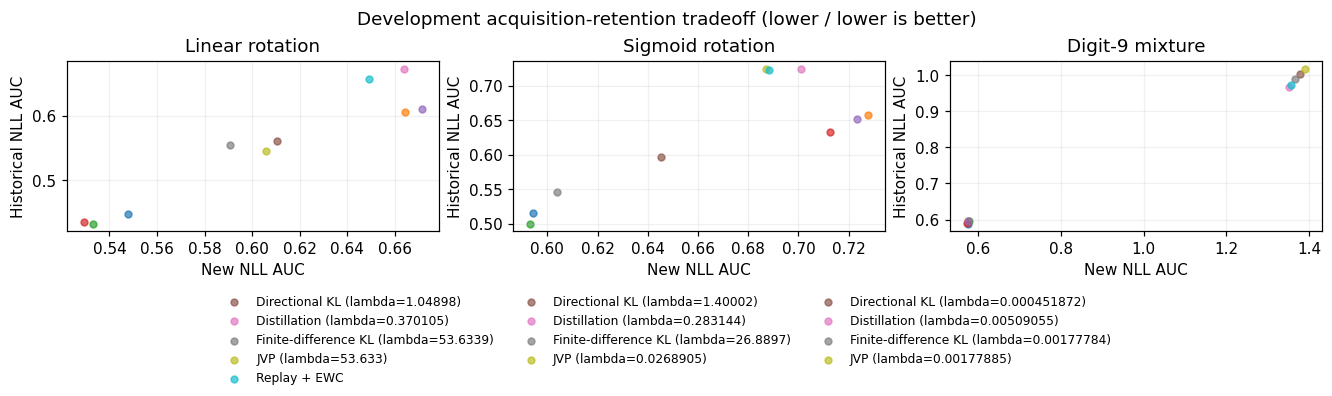

In [ ]:
# Rendered from sealed scalar metrics only; this cell performs no computation.

## Rotation results

Linear and sigmoid are separate conditions. Each panel uses the latest available phase shown in its title; earlier development is not pooled into confirmation.

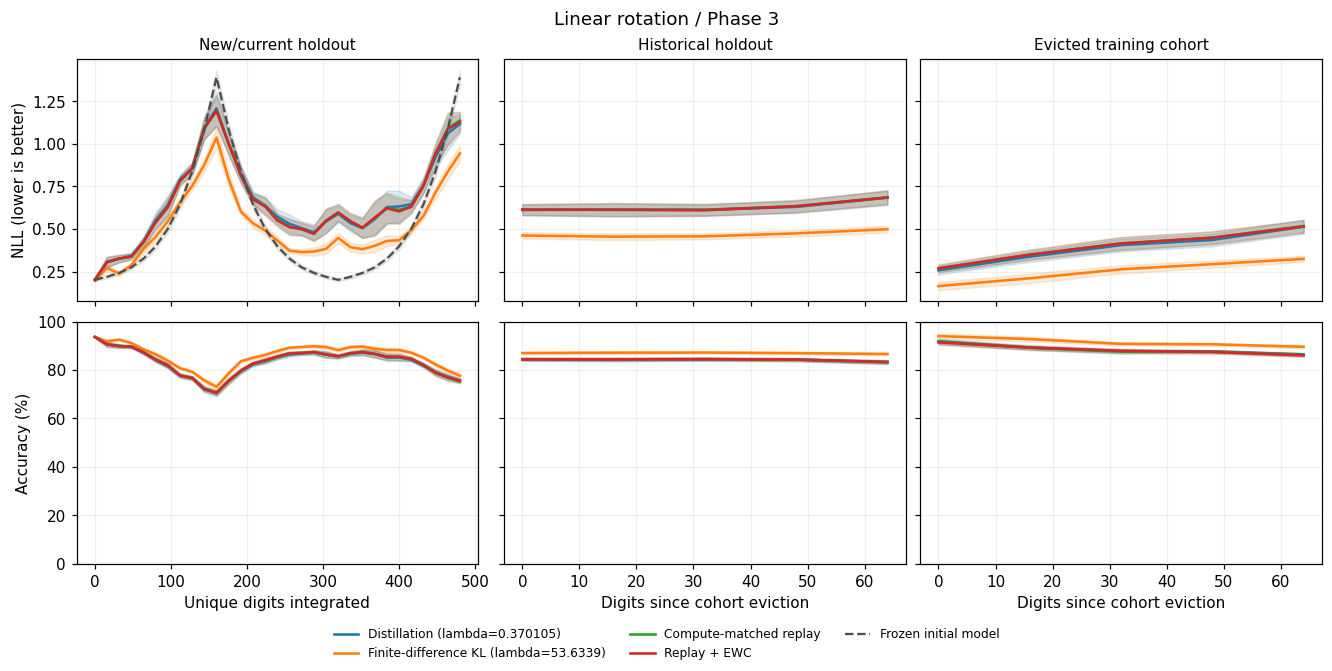

In [ ]:
# Rendered from sealed scalar metrics only; this cell performs no computation.

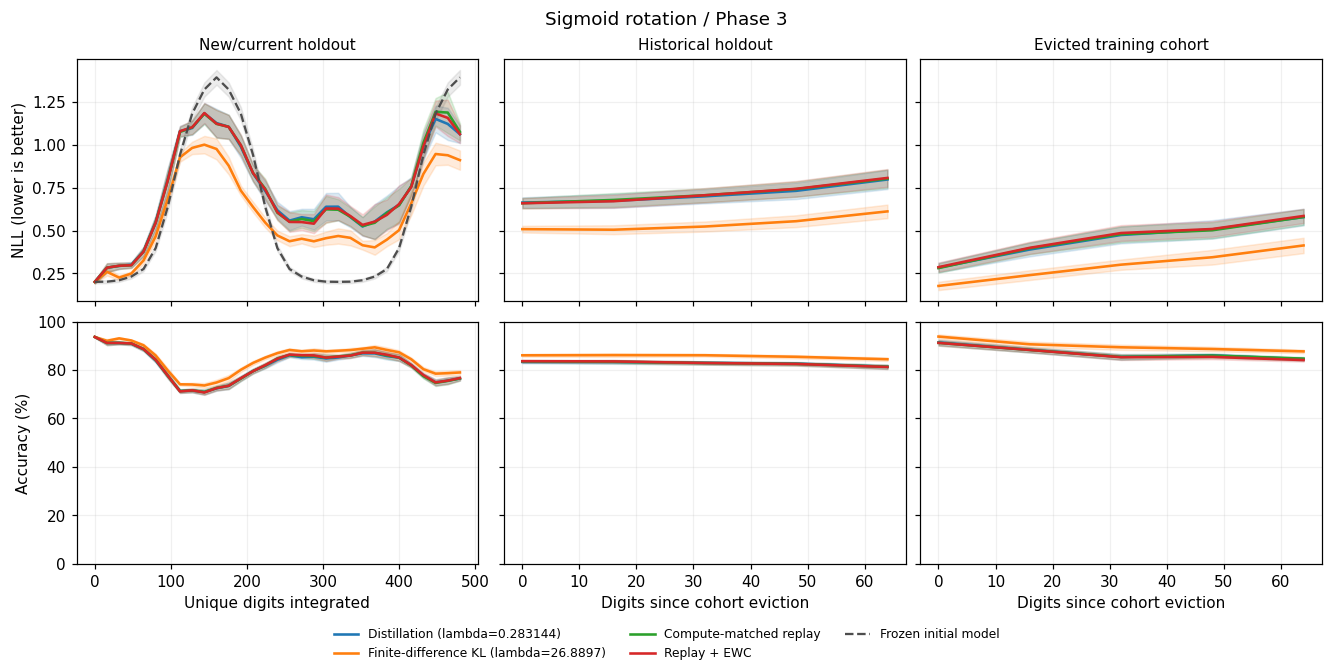

In [ ]:
# Rendered from sealed scalar metrics only; this cell performs no computation.

## Digit-9 mixture results

Expected online 9s per trajectory: **10.1**. Replay passes are not new observations. Pretraining cost is separate. Current and historical standardized PR need not differ systematically: mixture drift changes prevalence, not class-conditional images. Missing positive cohorts have undefined recall, not zero recall.

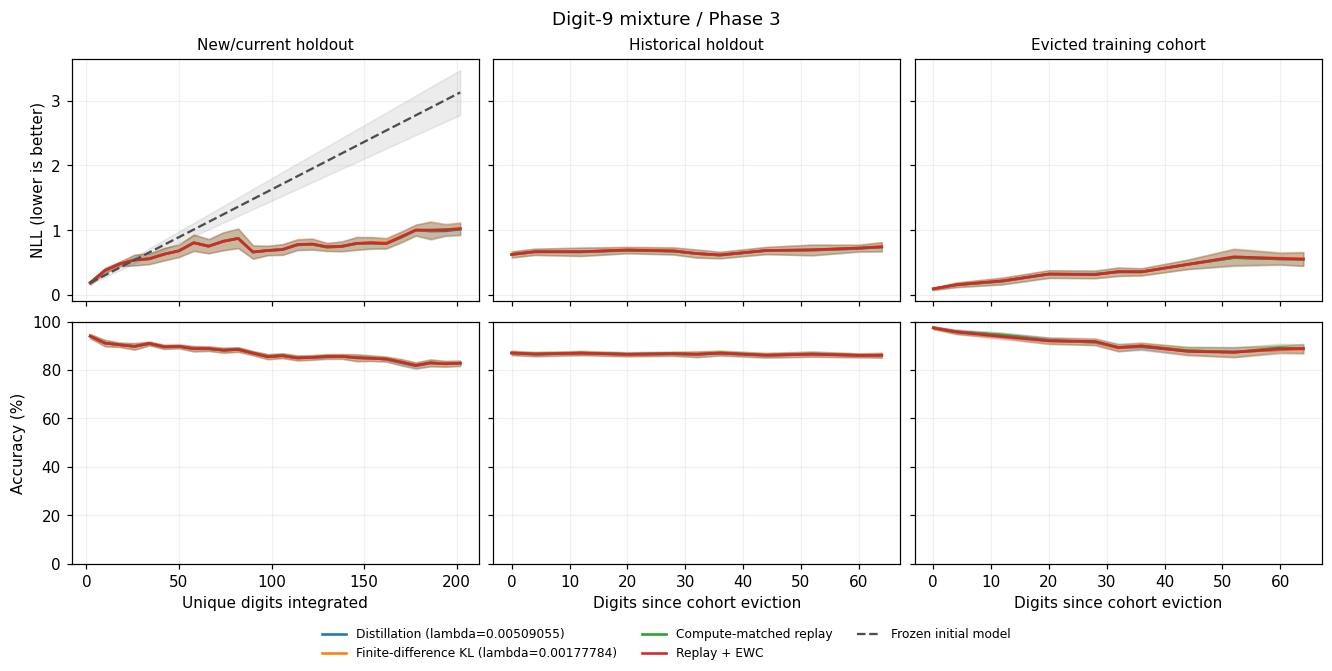

In [ ]:
# Rendered from sealed scalar metrics only; this cell performs no computation.

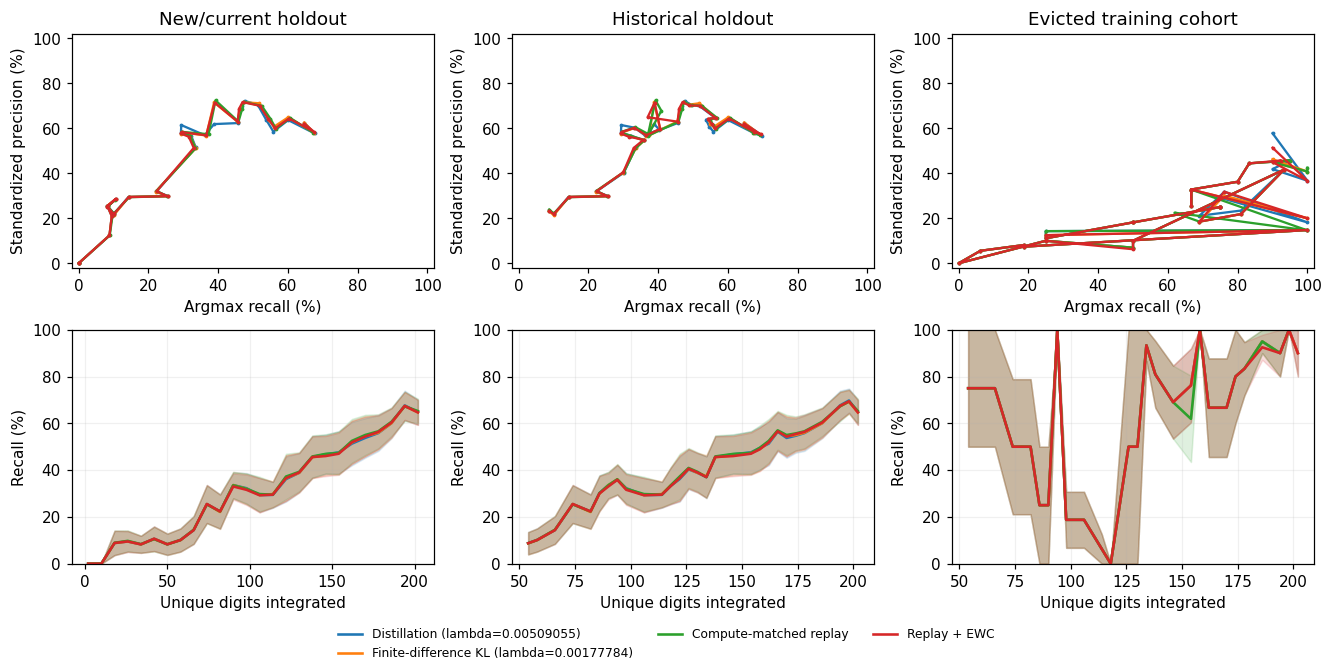

In [ ]:
# Rendered from sealed scalar metrics only; this cell performs no computation.

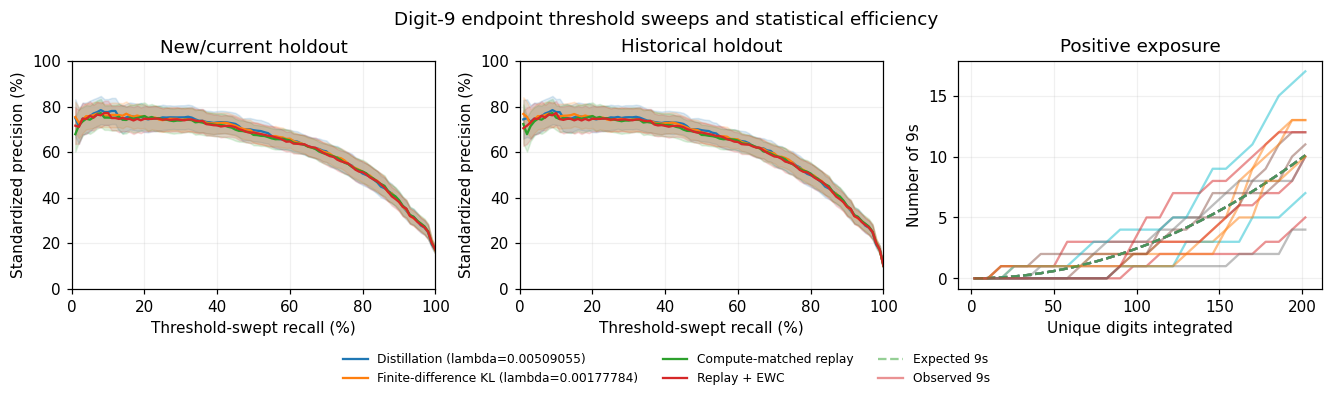

In [ ]:
# Rendered from sealed scalar metrics only; this cell performs no computation.

## Functional memory dependence

Reliance and vulnerability are functional interventions, not percentages of stored knowledge. Low vulnerability without useful acquisition may indicate lost plasticity. Raw Fisher traces are subordinate diagnostics. Low STM reliance after rehearsal is compatible with transfer, but does not distinguish it from capacity suppression. Fresh-arrival STM use is not measured by the pre-eviction snapshot.

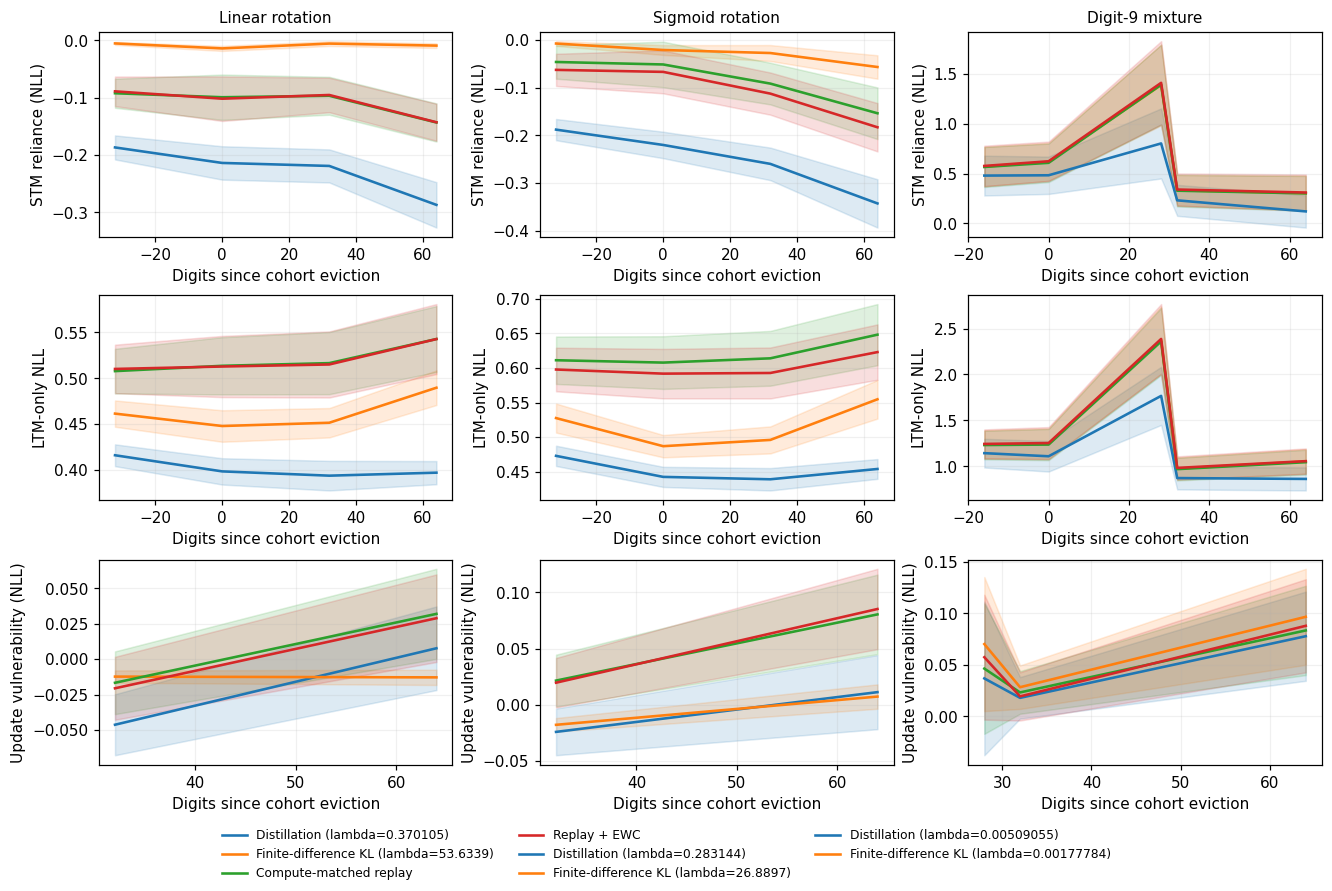

In [ ]:
# Rendered from sealed scalar metrics only; this cell performs no computation.

### Secondary curvature diagnostics

| Environment | Treatment | STM trace | LTM trace | Factor norm | Effective update norm |
| --- | --- | --- | --- | --- | --- |
| Sigmoid rotation | Distillation (lambda=0.283144) | 222.9 | 221.3 | 2.8 | pending |
| Sigmoid rotation | Finite-difference KL (lambda=26.8897) | 12.8 | 215.4 | 1.853 | pending |
| Sigmoid rotation | Compute-matched replay [7e9fff] | 177.1 | 180.5 | 2.812 | pending |
| Sigmoid rotation | Replay + EWC | 182.8 | 188.9 | 2.81 | pending |
| Digit-9 mixture | Distillation (lambda=0.00509055) | 124.8 | 177.9 | 3.746 | pending |
| Digit-9 mixture | Finite-difference KL (lambda=0.00177784) | 151 | 196.6 | 3.733 | pending |
| Digit-9 mixture | Compute-matched replay [727d9a] | 139.5 | 183.7 | 3.695 | pending |
| Digit-9 mixture | Replay + EWC | 143.1 | 181.9 | 3.717 | pending |

Replica means at latest checkpoints; full rows remain in unit JSON. Trace decreases alone do not establish consolidation.

### Sample and compute efficiency

| Environment | Treatment | Replicas | Digits integrated | Online seconds | Prequential NLL | Initial-task NLL |
| --- | --- | --- | --- | --- | --- | --- |
| Linear rotation | Distillation (lambda=0.370105) | 12 | 480 | 152.8 | 0.6895 | 1.135 |
| Linear rotation | Finite-difference KL (lambda=53.6339) | 12 | 480 | 203 | 0.5486 | 0.7822 |
| Linear rotation | Compute-matched replay [0246cf] | 12 | 480 | 123.6 | 0.6878 | 1.119 |
| Linear rotation | Replay + EWC | 12 | 480 | 113.9 | 0.6905 | 1.137 |
| Sigmoid rotation | Distillation (lambda=0.283144) | 12 | 480 | 153.5 | 0.7701 | 1.249 |
| Sigmoid rotation | Finite-difference KL (lambda=26.8897) | 12 | 480 | 206.2 | 0.6261 | 1.062 |
| Sigmoid rotation | Compute-matched replay [7e9fff] | 12 | 480 | 125.6 | 0.7699 | 1.229 |
| Sigmoid rotation | Replay + EWC | 12 | 480 | 114 | 0.7751 | 1.219 |
| Digit-9 mixture | Distillation (lambda=0.00509055) | 12 | 202 | 118.7 | 0.7308 | 0.8596 |
| Digit-9 mixture | Finite-difference KL (lambda=0.00177784) | 12 | 202 | 169 | 0.7331 | 0.8815 |
| Digit-9 mixture | Compute-matched replay [727d9a] | 12 | 202 | 95.01 | 0.7287 | 0.8654 |
| Digit-9 mixture | Replay + EWC | 12 | 202 | 88.17 | 0.731 | 0.8693 |

Latest observed endpoints; partial runs remain descriptive. Incoming NLL is weighted by arrival size within replica, then replicas are weighted equally. Initialization cost is separate from online compute.

## Conclusion

- **Linear rotation:** nominal 95% paired intervals favor the treatment on both NLL endpoints. mean current NLL AUC 0.5175 versus 0.5325 for the frozen initial model (descriptive); online time 1.78x replay/EWC.
- **Sigmoid rotation:** nominal 95% paired intervals favor the treatment on both NLL endpoints. mean current NLL AUC 0.5921 versus 0.6196 for the frozen initial model (descriptive); online time 1.81x replay/EWC.
- **Digit-9 mixture:** the paired intervals do not establish improvement on both NLL endpoints. mean current NLL AUC 0.7445 versus 1.658 for the frozen initial model (descriptive); online time 1.92x replay/EWC.

| Environment | Treatment | Endpoint | Pairs | Mean gain | Median | Favorable | 95% paired interval |
| --- | --- | --- | --- | --- | --- | --- | --- |
| Linear rotation | Distillation (lambda=0.370105) | New/current holdout | 12 | -0.003304 | -0.002129 | 4 | [-0.0119, 0.004115] |
| Linear rotation | Distillation (lambda=0.370105) | Historical holdout | 12 | 0.0001401 | -0.002382 | 4 | [-0.009445, 0.008859] |
| Linear rotation | Finite-difference KL (lambda=53.6339) | New/current holdout | 12 | 0.1399 | 0.1203 | 12 | [0.1139, 0.1753] |
| Linear rotation | Finite-difference KL (lambda=53.6339) | Historical holdout | 12 | 0.1599 | 0.1381 | 12 | [0.1283, 0.201] |
| Linear rotation | Compute-matched replay [0246cf] | New/current holdout | 12 | -0.0006297 | 0.0002429 | 7 | [-0.002737, 0.001031] |
| Linear rotation | Compute-matched replay [0246cf] | Historical holdout | 12 | -0.0008919 | 0.000711 | 7 | [-0.003923, 0.001526] |
| Sigmoid rotation | Distillation (lambda=0.283144) | New/current holdout | 12 | -0.0008559 | -0.004456 | 5 | [-0.006309, 0.004975] |
| Sigmoid rotation | Distillation (lambda=0.283144) | Historical holdout | 12 | 0.004508 | 0.0003098 | 6 | [-0.004718, 0.01379] |
| Sigmoid rotation | Finite-difference KL (lambda=26.8897) | New/current holdout | 12 | 0.1373 | 0.1189 | 12 | [0.1108, 0.1728] |
| Sigmoid rotation | Finite-difference KL (lambda=26.8897) | Historical holdout | 12 | 0.1773 | 0.1763 | 12 | [0.15, 0.2047] |
| Sigmoid rotation | Compute-matched replay [7e9fff] | New/current holdout | 12 | -0.002443 | -0.001984 | 3 | [-0.005342, -4.252e-05] |
| Sigmoid rotation | Compute-matched replay [7e9fff] | Historical holdout | 12 | -0.001068 | 0.0005654 | 7 | [-0.005066, 0.002783] |
| Digit-9 mixture | Distillation (lambda=0.00509055) | New/current holdout | 12 | 0.002871 | 0.004491 | 7 | [-0.001455, 0.006915] |
| Digit-9 mixture | Distillation (lambda=0.00509055) | Historical holdout | 12 | 0.00504 | 0.009224 | 7 | [-0.002026, 0.01188] |
| Digit-9 mixture | Finite-difference KL (lambda=0.00177784) | New/current holdout | 12 | -0.0007026 | -0.002009 | 5 | [-0.004384, 0.003282] |
| Digit-9 mixture | Finite-difference KL (lambda=0.00177784) | Historical holdout | 12 | -9.639e-05 | -0.001902 | 6 | [-0.005978, 0.005881] |
| Digit-9 mixture | Compute-matched replay [727d9a] | New/current holdout | 12 | 0.001685 | -0.0004889 | 5 | [-0.001616, 0.005642] |
| Digit-9 mixture | Compute-matched replay [727d9a] | Historical holdout | 12 | 0.001843 | -0.0004756 | 6 | [-0.00342, 0.007895] |

Gain is control minus treatment NLL AUC; positive favors treatment. Only matched complete trajectories and follow-up grids enter.

No best balance is declared automatically. Acquisition, evicted-data prediction, functional dependence and actual compute cost must be considered together. Small-replica intervals are fragile; a nonsignificant retention difference is not noninferiority. Development and confirmation are never pooled.

**Mechanism remains unresolved.** These predictive effects do not identify STM-to-LTM transfer; ordinary regularization or capacity suppression remain alternatives. Negative STM-removal harm means muting STM helps, not negative knowledge. Pre-eviction snapshots are after rehearsal. The calibrated larger-ceiling replay control used 56%--61% of the selected method's actual online time across environments; it is an allowance control, not a realized equal-time comparison. Persistent under-solving warnings limit interpretation to the configured bounded solver, not exact objective minimization.